In [1]:
# =====================================================================
# TWO-STAGE DNS TRAFFIC CLASSIFICATION
#
# Input:
# /content/drive/MyDrive/Objective2/
#
# Output:
# /content/drive/MyDrive/Objective2/output/
#
# Stage 1: Benign vs Malicious
# Stage 2: DNSCat2 vs DNSTT vs Iodine
#
# Models:
# Logistic Regression, Decision Tree, Random Forest, Linear SVM
#
# Figures:
# - KDE-only feature distributions
# - Blue, coffee, deep-red and pink colour palette
# - Legend below the KDE graph
# - No titles
# - PDF at 600 dpi
# - Best-model ROC curves
# - Best-model confusion matrices
# - Random Forest top-five feature importance
#
# Reviewer-proofing additions (Sections 35-38):
# - 5-fold stratified cross-validation
# - Stage-1 ResponseTime-feature ablation
# - End-to-end cascade evaluation
# - Hyperparameter and library-version export
# =====================================================================

In [2]:
# =====================================================================
# 1. MOUNT GOOGLE DRIVE
# =====================================================================

from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
# =====================================================================
# 2. IMPORT LIBRARIES
# =====================================================================

from pathlib import Path
import re
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from scipy.stats import gaussian_kde

from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, label_binarize
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

In [4]:
# =====================================================================
# 3. GLOBAL SETTINGS
# =====================================================================

RANDOM_STATE = 42

# Maximum rows used per class for KDE estimation.
# This affects plotting speed only.
# The complete dataset is still used for model training.
MAX_KDE_SAMPLES = 5000

# Remove an existing output folder before creating new results.
RESET_OUTPUT_FOLDER = True

In [5]:
# =====================================================================
# 4. FONT AND FIGURE SETTINGS
# =====================================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "DejaVu Serif",
        "Computer Modern",
        "Times New Roman"
    ],
    "font.size": 20,
    "axes.titlesize": 22,
    "axes.labelsize": 20,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 14,
    "figure.titlesize": 22
})


# Aesthetically pleasing KDE colours
KDE_COLOURS = {
    "Benign": "#2F6690",    # muted blue
    "DNSCat2": "#8B5E3C",   # coffee brown
    "DNSTT": "#9B1B30",     # deep red
    "Iodine": "#D36C9D"     # soft pink
}

LABEL_ORDER = [
    "Benign",
    "DNSCat2",
    "DNSTT",
    "Iodine"
]


# Colours used for ROC curves
ROC_COLOURS = {
    "Logistic Regression": "#2F6690",
    "Decision Tree": "#8B5E3C",
    "Random Forest": "#9B1B30",
    "SVM": "#D36C9D"
}

In [6]:
# =====================================================================
# 5. INPUT AND OUTPUT DIRECTORIES
# =====================================================================

BASE_DIR = Path(
    "/content/drive/MyDrive/Objective2"
)

OUTPUT_DIR = BASE_DIR / "output_cascading"

KDE_DIR = OUTPUT_DIR / "caskde_plots"
STAGE1_DIR = OUTPUT_DIR / "casstage1_results"
STAGE2_DIR = OUTPUT_DIR / "casstage2_results"
CLEANED_DATA_DIR = OUTPUT_DIR / "cascleaned_data"
MODEL_DIR = OUTPUT_DIR / "cassaved_models"


if RESET_OUTPUT_FOLDER and OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)


for directory in [
    OUTPUT_DIR,
    KDE_DIR,
    STAGE1_DIR,
    STAGE2_DIR,
    CLEANED_DATA_DIR,
    MODEL_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


print("Input directory :", BASE_DIR)
print("Output directory:", OUTPUT_DIR)

Input directory : /content/drive/MyDrive/Objective2
Output directory: /content/drive/MyDrive/Objective2/output_cascading


In [7]:
# =====================================================================
# 6. LOCATE THE FOUR CSV FILES
# =====================================================================

csv_files = sorted(
    BASE_DIR.glob("*.csv")
)


if len(csv_files) == 0:
    raise FileNotFoundError(
        f"No CSV files were found inside:\n{BASE_DIR}"
    )


print("\nCSV files found:")

for file_path in csv_files:
    print(" -", file_path.name)


def clean_filename(filename):
    """
    Convert a filename to lowercase alphanumeric text.
    """

    return re.sub(
        r"[^a-z0-9]",
        "",
        filename.lower()
    )


def find_csv(keyword):
    """
    Find a CSV file whose name contains the keyword.
    """

    cleaned_keyword = clean_filename(
        keyword
    )

    matches = []

    for file_path in csv_files:

        cleaned_file_name = clean_filename(
            file_path.stem
        )

        if cleaned_keyword in cleaned_file_name:
            matches.append(file_path)


    if len(matches) == 0:

        raise FileNotFoundError(
            f"No CSV file matching '{keyword}' was found "
            f"inside {BASE_DIR}"
        )


    if len(matches) > 1:

        print(
            f"Warning: multiple files matched '{keyword}'. "
            f"Using: {matches[0].name}"
        )


    return matches[0]


FILES = {
    "Benign": find_csv("benign"),
    "DNSCat2": find_csv("dnscat"),
    "DNSTT": find_csv("dnstt"),
    "Iodine": find_csv("iodine")
}


print("\nSelected files:")

for dataset_name, file_path in FILES.items():

    print(
        f"{dataset_name:8s}: {file_path.name}"
    )


CSV files found:
 - Benign.csv
 - Dnscat2.csv
 - Dnstt.csv
 - Iodine.csv

Selected files:
Benign  : Benign.csv
DNSCat2 : Dnscat2.csv
DNSTT   : Dnstt.csv
Iodine  : Iodine.csv


In [8]:
# =====================================================================
# 7. HELPER FUNCTIONS FOR COLUMN IDENTIFICATION
# =====================================================================

def normalise_column_name(column_name):
    """
    Remove spaces and punctuation from a column name.
    """

    return re.sub(
        r"[^a-z0-9]",
        "",
        str(column_name).lower()
    )


def find_column_case_insensitive(
    dataframe,
    possible_names
):
    """
    Find a dataframe column using several possible names.
    """

    available_columns = {
        normalise_column_name(column): column
        for column in dataframe.columns
    }


    for possible_name in possible_names:

        normalised_name = normalise_column_name(
            possible_name
        )

        if normalised_name in available_columns:

            return available_columns[
                normalised_name
            ]


    return None

In [9]:
# =====================================================================
# 8. READ ALL FOUR CSV FILES
# =====================================================================

frames = []
raw_file_summary = []


for dataset_name, file_path in FILES.items():

    print(
        f"\nReading {dataset_name}: "
        f"{file_path.name}"
    )

    dataframe = pd.read_csv(
        file_path,
        low_memory=False
    )


    # Strip spaces from column names.
    dataframe.columns = [
        str(column).strip()
        for column in dataframe.columns
    ]


    # Find and standardise the Class column.
    class_column = find_column_case_insensitive(
        dataframe,
        ["Class"]
    )


    if class_column is None:

        raise ValueError(
            f"Class column was not found in "
            f"{file_path.name}"
        )


    if class_column != "Class":

        dataframe = dataframe.rename(
            columns={
                class_column: "Class"
            }
        )


    # Find and standardise the Label column.
    label_column = find_column_case_insensitive(
        dataframe,
        ["Label"]
    )


    if label_column is None:

        dataframe["Label"] = "Benign"

    elif label_column != "Label":

        dataframe = dataframe.rename(
            columns={
                label_column: "Label"
            }
        )


    dataframe["DatasetSource"] = dataset_name


    numeric_dataframe = dataframe.select_dtypes(
        include=[np.number]
    )


    if numeric_dataframe.shape[1] > 0:

        infinite_values = int(
            np.isinf(
                numeric_dataframe.to_numpy(
                    dtype=float
                )
            ).sum()
        )

    else:

        infinite_values = 0


    raw_file_summary.append({
        "Dataset": dataset_name,
        "Filename": file_path.name,
        "Rows": len(dataframe),
        "Columns": dataframe.shape[1],
        "MissingValues":
            int(dataframe.isna().sum().sum()),
        "InfiniteValues":
            infinite_values,
        "ExactFullRowDuplicates":
            int(dataframe.duplicated().sum())
    })


    frames.append(dataframe)


raw_summary_df = pd.DataFrame(
    raw_file_summary
)


raw_summary_df.to_csv(
    OUTPUT_DIR / "raw_file_summary.csv",
    index=False
)


print("\nRaw-file summary:")

display(
    raw_summary_df
)


raw_data = pd.concat(
    frames,
    ignore_index=True,
    sort=False
)


print(
    "\nCombined raw-data shape:",
    raw_data.shape
)


Reading Benign: Benign.csv

Reading DNSCat2: Dnscat2.csv

Reading DNSTT: Dnstt.csv

Reading Iodine: Iodine.csv

Raw-file summary:


,Dataset,Filename,Rows,Columns,MissingValues,InfiniteValues,ExactFullRowDuplicates
0,Benign,Benign.csv,95234,37,0,0,0
1,DNSCat2,Dnscat2.csv,105009,37,0,0,0
2,DNSTT,Dnstt.csv,90334,37,0,0,0
3,Iodine,Iodine.csv,140000,37,0,0,0



Combined raw-data shape: (430577, 37)


In [10]:
# =====================================================================
# 9. NORMALISE CLASS AND TOOL LABELS
# =====================================================================

raw_data["Class"] = (
    raw_data["Class"]
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({
        "normal": "benign",
        "attack": "malicious"
    })
    .str.title()
)


def standardise_tool_label(value):
    """
    Standardise tool-name spellings.
    """

    cleaned_value = str(value).strip().lower()


    if "benign" in cleaned_value:
        return "Benign"


    if "dnscat" in cleaned_value:
        return "DNSCat2"


    if "dnstt" in cleaned_value:
        return "DNSTT"


    if "iodine" in cleaned_value:
        return "Iodine"


    return str(value).strip()


raw_data["Label"] = (
    raw_data["Label"]
    .apply(standardise_tool_label)
)


# Force every benign row to use the Benign tool label.
raw_data.loc[
    raw_data["Class"]
    .str.lower()
    .eq("benign"),
    "Label"
] = "Benign"


print("\nClass values:")

print(
    raw_data["Class"]
    .value_counts(dropna=False)
)


print("\nTool-label values:")

print(
    raw_data["Label"]
    .value_counts(dropna=False)
)


Class values:
Class
Malicious    335343
Benign        95234
Name: count, dtype: int64

Tool-label values:
Label
Iodine     140000
DNSCat2    105009
Benign      95234
DNSTT       90334
Name: count, dtype: int64


In [11]:
# =====================================================================
# 10. REMOVE SOURCE IP, DESTINATION IP, PORTS AND TIMESTAMP
# =====================================================================

columns_to_exclude = [
    "SourceIP",
    "Source IP",
    "SrcIP",
    "Src IP",

    "DestinationIP",
    "Destination IP",
    "DestIP",
    "DstIP",
    "Dst IP",

    "SourcePort",
    "Source Port",
    "SrcPort",
    "Src Port",

    "DestinationPort",
    "Destination Port",
    "DestPort",
    "DstPort",
    "Dst Port",

    "TimeStamp",
    "Timestamp",
    "Time Stamp",
    "DateTime",
    "Date Time",
    "CaptureTime",
    "Capture Time",

    "DatasetSource"
]


normalised_excluded_names = {
    normalise_column_name(column)
    for column in columns_to_exclude
}


actual_columns_to_remove = [
    column
    for column in raw_data.columns
    if normalise_column_name(column)
    in normalised_excluded_names
]


print("\nColumns removed:")

for column in actual_columns_to_remove:
    print(" -", column)


data = raw_data.drop(
    columns=actual_columns_to_remove,
    errors="ignore"
).copy()


Columns removed:
 - SourceIP
 - DestinationIP
 - SourcePort
 - DestinationPort
 - TimeStamp
 - DatasetSource


In [12]:
# =====================================================================
# 11. IDENTIFY FEATURE COLUMNS
# =====================================================================

TARGET_COLUMNS = [
    "Class",
    "Label"
]


FEATURE_COLUMNS = [
    column
    for column in data.columns
    if column not in TARGET_COLUMNS
]


print(
    "\nNumber of retained model features:",
    len(FEATURE_COLUMNS)
)


print("\nFeature columns:")

for feature_number, feature in enumerate(
    FEATURE_COLUMNS,
    start=1
):

    print(
        f"{feature_number:02d}. {feature}"
    )


Number of retained model features: 29

Feature columns:
01. Duration
02. FlowBytesSent
03. FlowSentRate
04. FlowBytesReceived
05. FlowReceivedRate
06. PacketLengthVariance
07. PacketLengthStandardDeviation
08. PacketLengthMean
09. PacketLengthMedian
10. PacketLengthMode
11. PacketLengthSkewFromMedian
12. PacketLengthSkewFromMode
13. PacketLengthCoefficientofVariation
14. PacketTimeVariance
15. PacketTimeStandardDeviation
16. PacketTimeMean
17. PacketTimeMedian
18. PacketTimeMode
19. PacketTimeSkewFromMedian
20. PacketTimeSkewFromMode
21. PacketTimeCoefficientofVariation
22. ResponseTimeTimeVariance
23. ResponseTimeTimeStandardDeviation
24. ResponseTimeTimeMean
25. ResponseTimeTimeMedian
26. ResponseTimeTimeMode
27. ResponseTimeTimeSkewFromMedian
28. ResponseTimeTimeSkewFromMode
29. ResponseTimeTimeCoefficientofVariation


In [13]:
# =====================================================================
# 12. CONVERT FEATURES TO NUMERIC
# =====================================================================

for feature in FEATURE_COLUMNS:

    data[feature] = pd.to_numeric(
        data[feature],
        errors="coerce"
    )


# Convert infinity to missing values.
data[FEATURE_COLUMNS] = (
    data[FEATURE_COLUMNS]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)

In [14]:
# =====================================================================
# 13. HANDLE MISSING VALUES
# =====================================================================

missing_values_before = int(
    data[FEATURE_COLUMNS]
    .isna()
    .sum()
    .sum()
)


print(
    "\nMissing values before imputation:",
    missing_values_before
)


for feature in FEATURE_COLUMNS:

    if data[feature].isna().any():

        feature_mean = data[feature].mean()


        if pd.isna(feature_mean):
            feature_mean = 0.0


        data[feature] = (
            data[feature]
            .fillna(feature_mean)
        )


missing_values_after = int(
    data[FEATURE_COLUMNS]
    .isna()
    .sum()
    .sum()
)


print(
    "Missing values after imputation :",
    missing_values_after
)


Missing values before imputation: 0
Missing values after imputation : 0


In [15]:
# =====================================================================
# 14. REMOVE DUPLICATES AFTER IDENTIFIERS ARE REMOVED
# =====================================================================

rows_before_duplicate_removal = len(
    data
)


data = (
    data
    .drop_duplicates()
    .reset_index(drop=True)
)


rows_after_duplicate_removal = len(
    data
)


duplicates_removed = (
    rows_before_duplicate_removal
    - rows_after_duplicate_removal
)


print(
    "\nRows before duplicate removal:",
    rows_before_duplicate_removal
)

print(
    "Rows after duplicate removal :",
    rows_after_duplicate_removal
)

print(
    "Duplicate rows removed       :",
    duplicates_removed
)


Rows before duplicate removal: 430577
Rows after duplicate removal : 407623
Duplicate rows removed       : 22954


In [16]:
# =====================================================================
# 15. REMOVE CONTRADICTORY FEATURE VECTORS
# =====================================================================
#
# A contradictory feature vector has exactly the same model features
# but different class or tool labels.
# Such rows can create unavoidable label conflict.
# =====================================================================

data["FeatureVectorHash"] = (
    pd.util.hash_pandas_object(
        data[FEATURE_COLUMNS],
        index=False
    )
    .astype(str)
)


data["CombinedTarget"] = (
    data["Class"].astype(str)
    + "_"
    + data["Label"].astype(str)
)


target_count_per_hash = (
    data
    .groupby("FeatureVectorHash")
    ["CombinedTarget"]
    .nunique()
)


contradictory_hashes = (
    target_count_per_hash[
        target_count_per_hash > 1
    ]
    .index
)


contradictory_rows = int(
    data["FeatureVectorHash"]
    .isin(contradictory_hashes)
    .sum()
)


print(
    "\nContradictory feature groups:",
    len(contradictory_hashes)
)

print(
    "Rows in contradictory groups:",
    contradictory_rows
)


if contradictory_rows > 0:

    data = data.loc[
        ~data["FeatureVectorHash"]
        .isin(contradictory_hashes)
    ].copy()


data = (
    data
    .drop(
        columns=["CombinedTarget"]
    )
    .reset_index(drop=True)
)


print(
    "Rows retained after contradiction removal:",
    len(data)
)


Contradictory feature groups: 1
Rows in contradictory groups: 2
Rows retained after contradiction removal: 407621


In [17]:
# =====================================================================
# 16. POST-PREPROCESSING SUMMARY
# =====================================================================

post_preprocessing_summary = pd.DataFrame([{
    "RawRows":
        len(raw_data),

    "RowsBeforeDuplicateRemoval":
        rows_before_duplicate_removal,

    "RowsAfterDuplicateRemoval":
        rows_after_duplicate_removal,

    "DuplicatesRemoved":
        duplicates_removed,

    "ContradictoryRowsRemoved":
        contradictory_rows,

    "FinalRows":
        len(data),

    "RetainedFeatures":
        len(FEATURE_COLUMNS),

    "MissingValues":
        int(
            data[FEATURE_COLUMNS]
            .isna()
            .sum()
            .sum()
        ),

    "InfiniteValues":
        int(
            np.isinf(
                data[FEATURE_COLUMNS]
                .to_numpy(dtype=float)
            ).sum()
        )
}])


post_preprocessing_summary.to_csv(
    OUTPUT_DIR /
    "post_preprocessing_summary.csv",
    index=False
)


print("\nPost-preprocessing summary:")

display(
    post_preprocessing_summary
)


Post-preprocessing summary:


,RawRows,RowsBeforeDuplicateRemoval,RowsAfterDuplicateRemoval,DuplicatesRemoved,ContradictoryRowsRemoved,FinalRows,RetainedFeatures,MissingValues,InfiniteValues
0,430577,430577,407623,22954,2,407621,29,0,0


In [18]:
# =====================================================================
# 17. SAVE FEATURE STATISTICS
# =====================================================================

feature_summary = pd.DataFrame(
    index=FEATURE_COLUMNS
)


feature_summary["Minimum"] = (
    data[FEATURE_COLUMNS]
    .min()
)


feature_summary["Maximum"] = (
    data[FEATURE_COLUMNS]
    .max()
)


feature_summary["Mean"] = (
    data[FEATURE_COLUMNS]
    .mean()
)


feature_summary["Median"] = (
    data[FEATURE_COLUMNS]
    .median()
)


feature_summary["StandardDeviation"] = (
    data[FEATURE_COLUMNS]
    .std()
)


feature_summary["Skewness"] = (
    data[FEATURE_COLUMNS]
    .skew()
)


feature_summary["UniqueValues"] = (
    data[FEATURE_COLUMNS]
    .nunique()
)


feature_summary["Minus1Count"] = (
    data[FEATURE_COLUMNS] == -1
).sum()


feature_summary["Minus10Count"] = (
    data[FEATURE_COLUMNS] == -10
).sum()


feature_summary.index.name = "Feature"


feature_summary.reset_index().to_csv(
    OUTPUT_DIR /
    "post_preprocessing_feature_summary.csv",
    index=False
)

In [19]:
# =====================================================================
# 18. GENERATE KDE-ONLY FEATURE PLOTS
# =====================================================================

random_generator = np.random.default_rng(
    RANDOM_STATE
)


print("\nGenerating KDE plots...")


for feature_number, feature in enumerate(
    FEATURE_COLUMNS,
    start=1
):

    all_values = (
        data[feature]
        .to_numpy(dtype=float)
    )


    all_values = all_values[
        np.isfinite(all_values)
    ]


    if len(all_values) < 2:

        print(
            f"Skipping {feature}: "
            "insufficient values"
        )

        continue


    # Display between the 0.5th and 99.5th percentiles.
    # This clipping is for plots only.
    lower_limit = np.quantile(
        all_values,
        0.005
    )


    upper_limit = np.quantile(
        all_values,
        0.995
    )


    if (
        not np.isfinite(lower_limit)
        or not np.isfinite(upper_limit)
    ):

        lower_limit = np.min(
            all_values
        )

        upper_limit = np.max(
            all_values
        )


    if lower_limit == upper_limit:

        lower_limit -= 0.5
        upper_limit += 0.5


    x_grid = np.linspace(
        lower_limit,
        upper_limit,
        500
    )


    figure, axis = plt.subplots(
        figsize=(10.0, 7.0)
    )


    plotted_curve_count = 0


    for label in LABEL_ORDER:

        label_values = (
            data.loc[
                data["Label"].eq(label),
                feature
            ]
            .to_numpy(dtype=float)
        )


        label_values = label_values[
            np.isfinite(label_values)
        ]


        # Retain values within the visualisation interval.
        label_values = label_values[
            (label_values >= lower_limit)
            &
            (label_values <= upper_limit)
        ]


        if len(label_values) < 2:
            continue


        # Use a random sample for KDE estimation.
        if len(label_values) > MAX_KDE_SAMPLES:

            selected_indices = (
                random_generator.choice(
                    len(label_values),
                    size=MAX_KDE_SAMPLES,
                    replace=False
                )
            )


            kde_values = label_values[
                selected_indices
            ]

        else:

            kde_values = label_values


        # Gaussian KDE cannot process a fully constant array.
        if np.std(kde_values) == 0:

            jitter_standard_deviation = max(
                abs(kde_values[0]) * 1e-8,
                1e-8
            )


            kde_values = (
                kde_values
                +
                random_generator.normal(
                    loc=0.0,
                    scale=jitter_standard_deviation,
                    size=len(kde_values)
                )
            )


        try:

            kde_model = gaussian_kde(
                kde_values,
                bw_method="scott"
            )


            density = kde_model(
                x_grid
            )


            axis.plot(
                x_grid,
                density,
                color=KDE_COLOURS[label],
                linewidth=3.0,
                label=label
            )


            plotted_curve_count += 1


        except (
            np.linalg.LinAlgError,
            ValueError
        ) as error:

            print(
                f"Could not estimate KDE for "
                f"{feature}, {label}: {error}"
            )


    axis.set_xlabel(
        feature
    )


    axis.set_ylabel(
        "Density"
    )


    axis.set_xlim(
        lower_limit,
        upper_limit
    )


    axis.grid(False)


    axis.spines["top"].set_visible(
        False
    )


    axis.spines["right"].set_visible(
        False
    )


    # Place legend below the graph.
    if plotted_curve_count > 0:

        axis.legend(
            loc="upper center",
            bbox_to_anchor=(0.5, -0.20),
            ncol=4,
            frameon=False,
            columnspacing=1.8,
            handlelength=2.5
        )


    # No title is added.
    figure.subplots_adjust(
        bottom=0.27
    )


    safe_feature_name = re.sub(
        r"[^A-Za-z0-9_-]",
        "_",
        feature
    )


    kde_output_path = (
        KDE_DIR
        /
        f"{feature_number:02d}_"
        f"{safe_feature_name}_kde.pdf"
    )


    figure.savefig(
        kde_output_path,
        format="pdf",
        dpi=600,
        bbox_inches="tight"
    )


    plt.close(
        figure
    )


    print(
        f"{feature_number:02d}/"
        f"{len(FEATURE_COLUMNS)} "
        f"saved: {kde_output_path.name}"
    )


print(
    "\nNumber of KDE PDFs:",
    len(list(KDE_DIR.glob("*.pdf")))
)


Generating KDE plots...
01/29 saved: 01_Duration_kde.pdf
02/29 saved: 02_FlowBytesSent_kde.pdf
03/29 saved: 03_FlowSentRate_kde.pdf
04/29 saved: 04_FlowBytesReceived_kde.pdf
05/29 saved: 05_FlowReceivedRate_kde.pdf
06/29 saved: 06_PacketLengthVariance_kde.pdf
07/29 saved: 07_PacketLengthStandardDeviation_kde.pdf
08/29 saved: 08_PacketLengthMean_kde.pdf
09/29 saved: 09_PacketLengthMedian_kde.pdf
10/29 saved: 10_PacketLengthMode_kde.pdf
11/29 saved: 11_PacketLengthSkewFromMedian_kde.pdf
12/29 saved: 12_PacketLengthSkewFromMode_kde.pdf
13/29 saved: 13_PacketLengthCoefficientofVariation_kde.pdf
14/29 saved: 14_PacketTimeVariance_kde.pdf
15/29 saved: 15_PacketTimeStandardDeviation_kde.pdf
16/29 saved: 16_PacketTimeMean_kde.pdf
17/29 saved: 17_PacketTimeMedian_kde.pdf
18/29 saved: 18_PacketTimeMode_kde.pdf
19/29 saved: 19_PacketTimeSkewFromMedian_kde.pdf
20/29 saved: 20_PacketTimeSkewFromMode_kde.pdf
21/29 saved: 21_PacketTimeCoefficientofVariation_kde.pdf
22/29 saved: 22_ResponseTimeTimeVa

In [20]:
# =====================================================================
# 19. CREATE STAGE-1 DATASET
# =====================================================================

stage1_data = data[
    FEATURE_COLUMNS + ["Class"]
].copy()


stage1_data["Target"] = (
    stage1_data["Class"]
    .str.lower()
    .map({
        "benign": 0,
        "malicious": 1
    })
)


stage1_data = (
    stage1_data
    .dropna(subset=["Target"])
    .reset_index(drop=True)
)


stage1_data["Target"] = (
    stage1_data["Target"]
    .astype(int)
)


print("\nStage-1 distribution:")

stage1_distribution = (
    stage1_data["Class"]
    .value_counts()
    .rename_axis("Class")
    .reset_index(name="Rows")
)


stage1_distribution["Percentage"] = (
    stage1_distribution["Rows"]
    / len(stage1_data)
    * 100
)


display(
    stage1_distribution
)


stage1_distribution.to_csv(
    STAGE1_DIR /
    "class_distribution.csv",
    index=False
)


Stage-1 distribution:


,Class,Rows,Percentage
0,Malicious,335337,82.266861
1,Benign,72284,17.733139


In [21]:
# =====================================================================
# 20. CREATE STAGE-2 DATASET
# =====================================================================

stage2_data = data.loc[
    data["Class"]
    .str.lower()
    .eq("malicious"),
    FEATURE_COLUMNS + ["Label"]
].copy()


stage2_mapping = {
    "DNSCat2": 0,
    "DNSTT": 1,
    "Iodine": 2
}


stage2_data["Target"] = (
    stage2_data["Label"]
    .map(stage2_mapping)
)


stage2_data = (
    stage2_data
    .dropna(subset=["Target"])
    .reset_index(drop=True)
)


stage2_data["Target"] = (
    stage2_data["Target"]
    .astype(int)
)


print("\nStage-2 distribution:")

stage2_distribution = (
    stage2_data["Label"]
    .value_counts()
    .rename_axis("Tool")
    .reset_index(name="Rows")
)


stage2_distribution["Percentage"] = (
    stage2_distribution["Rows"]
    / len(stage2_data)
    * 100
)


display(
    stage2_distribution
)


stage2_distribution.to_csv(
    STAGE2_DIR /
    "tool_distribution.csv",
    index=False
)


Stage-2 distribution:


,Tool,Rows,Percentage
0,Iodine,139995,41.747555
1,DNSCat2,105009,31.314469
2,DNSTT,90333,26.937976


In [22]:
# =====================================================================
# 21. SAVE CLEANED DATASETS
# =====================================================================

stage1_data.to_csv(
    CLEANED_DATA_DIR /
    "stage1_cleaned_data.csv.gz",
    index=False,
    compression="gzip"
)


stage2_data.to_csv(
    CLEANED_DATA_DIR /
    "stage2_cleaned_data.csv.gz",
    index=False,
    compression="gzip"
)

In [23]:
# =====================================================================
# 22. TRAIN, VALIDATION AND TEST SPLIT
# =====================================================================

def create_three_way_split(
    features,
    target,
    train_size=0.70,
    validation_size=0.15,
    test_size=0.15,
    random_state=42
):
    """
    Create stratified 70:15:15 splits.
    """

    total_size = (
        train_size
        + validation_size
        + test_size
    )


    if not np.isclose(
        total_size,
        1.0
    ):

        raise ValueError(
            "Train, validation and test "
            "sizes must sum to 1."
        )


    features_train, features_temporary, \
    target_train, target_temporary = (
        train_test_split(
            features,
            target,
            test_size=(
                validation_size
                + test_size
            ),
            stratify=target,
            random_state=random_state
        )
    )


    relative_test_size = (
        test_size
        /
        (
            validation_size
            + test_size
        )
    )


    features_validation, features_test, \
    target_validation, target_test = (
        train_test_split(
            features_temporary,
            target_temporary,
            test_size=relative_test_size,
            stratify=target_temporary,
            random_state=random_state
        )
    )


    return (
        features_train,
        features_validation,
        features_test,
        target_train,
        target_validation,
        target_test
    )


# Stage 1 split
X1 = stage1_data[
    FEATURE_COLUMNS
]

y1 = stage1_data[
    "Target"
]


(
    X1_train,
    X1_validation,
    X1_test,
    y1_train,
    y1_validation,
    y1_test
) = create_three_way_split(
    X1,
    y1,
    random_state=RANDOM_STATE
)


# Stage 2 split
X2 = stage2_data[
    FEATURE_COLUMNS
]

y2 = stage2_data[
    "Target"
]


(
    X2_train,
    X2_validation,
    X2_test,
    y2_train,
    y2_validation,
    y2_test
) = create_three_way_split(
    X2,
    y2,
    random_state=RANDOM_STATE
)


print("\nStage-1 split sizes:")

print(
    "Training  :",
    len(X1_train)
)

print(
    "Validation:",
    len(X1_validation)
)

print(
    "Testing   :",
    len(X1_test)
)


print("\nStage-2 split sizes:")

print(
    "Training  :",
    len(X2_train)
)

print(
    "Validation:",
    len(X2_validation)
)

print(
    "Testing   :",
    len(X2_test)
)


Stage-1 split sizes:
Training  : 285334
Validation: 61143
Testing   : 61144

Stage-2 split sizes:
Training  : 234735
Validation: 50301
Testing   : 50301


In [24]:
# =====================================================================
# 23. SAVE SPLIT DISTRIBUTIONS
# =====================================================================

def create_split_distribution(
    target_train,
    target_validation,
    target_test,
    class_names
):

    distribution_rows = []


    for split_name, target_values in [
        ("Training", target_train),
        ("Validation", target_validation),
        ("Testing", target_test)
    ]:

        class_counts = (
            target_values
            .value_counts()
            .sort_index()
        )


        for class_index, class_name in enumerate(
            class_names
        ):

            row_count = int(
                class_counts.get(
                    class_index,
                    0
                )
            )


            distribution_rows.append({
                "Split": split_name,
                "ClassIndex": class_index,
                "ClassName": class_name,
                "Rows": row_count,
                "Percentage":
                    row_count
                    / len(target_values)
                    * 100
            })


    return pd.DataFrame(
        distribution_rows
    )


stage1_split_distribution = (
    create_split_distribution(
        y1_train,
        y1_validation,
        y1_test,
        ["Benign", "Malicious"]
    )
)


stage1_split_distribution.to_csv(
    STAGE1_DIR /
    "split_distribution.csv",
    index=False
)


stage2_split_distribution = (
    create_split_distribution(
        y2_train,
        y2_validation,
        y2_test,
        [
            "DNSCat2",
            "DNSTT",
            "Iodine"
        ]
    )
)


stage2_split_distribution.to_csv(
    STAGE2_DIR /
    "split_distribution.csv",
    index=False
)

In [25]:
# =====================================================================
# 24. DEFINE MODEL PIPELINES
# =====================================================================

scaled_preprocessing = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="mean"
        )
    ),
    (
        "scaler",
        RobustScaler()
    )
])


MODELS = {
    "Logistic Regression": Pipeline([
        (
            "preprocessing",
            clone(scaled_preprocessing)
        ),
        (
            "classifier",
            LogisticRegression(
                solver="saga",
                max_iter=1500,
                class_weight="balanced",
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        )
    ]),

    "Decision Tree": Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="mean"
            )
        ),
        (
            "classifier",
            DecisionTreeClassifier(
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ]),

    "Random Forest": Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="mean"
            )
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        )
    ]),

    # Linear SVM is used because the dataset contains
    # hundreds of thousands of observations.
    "SVM": Pipeline([
        (
            "preprocessing",
            clone(scaled_preprocessing)
        ),
        (
            "classifier",
            LinearSVC(
                class_weight="balanced",
                max_iter=10000,
                random_state=RANDOM_STATE
            )
        )
    ])
}

In [26]:
# =====================================================================
# 25. MODEL EVALUATION FUNCTIONS
# =====================================================================

def obtain_model_scores(
    model,
    features
):
    """
    Return probability or decision-function scores.
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        return model.predict_proba(
            features
        )


    if hasattr(
        model,
        "decision_function"
    ):

        return model.decision_function(
            features
        )


    raise AttributeError(
        "The model does not provide "
        "predict_proba or decision_function."
    )


def calculate_macro_roc_auc(
    target_true,
    score_values,
    class_labels
):
    """
    Calculate binary or multiclass macro ROC AUC.
    """

    class_labels = np.asarray(
        class_labels
    )


    score_values = np.asarray(
        score_values
    )


    # Binary classification
    if len(class_labels) == 2:

        if score_values.ndim == 2:

            positive_scores = (
                score_values[:, 1]
            )

        else:

            positive_scores = (
                score_values
            )


        return roc_auc_score(
            target_true,
            positive_scores
        )


    # Multiclass one-vs-rest calculation
    binary_target = label_binarize(
        target_true,
        classes=class_labels
    )


    per_class_auc = []


    for class_index in range(
        len(class_labels)
    ):

        class_auc = roc_auc_score(
            binary_target[:, class_index],
            score_values[:, class_index]
        )


        per_class_auc.append(
            class_auc
        )


    return float(
        np.mean(per_class_auc)
    )


def calculate_model_metrics(
    model,
    features,
    target,
    class_labels
):
    """
    Calculate performance metrics.
    """

    predictions = model.predict(
        features
    )


    score_values = obtain_model_scores(
        model,
        features
    )


    metrics = {
        "Accuracy":
            accuracy_score(
                target,
                predictions
            ),

        "Precision":
            precision_score(
                target,
                predictions,
                average="macro",
                zero_division=0
            ),

        "Recall":
            recall_score(
                target,
                predictions,
                average="macro",
                zero_division=0
            ),

        "F1":
            f1_score(
                target,
                predictions,
                average="macro",
                zero_division=0
            ),

        "ROC_AUC":
            calculate_macro_roc_auc(
                target,
                score_values,
                class_labels
            )
    }


    return metrics

In [27]:
# =====================================================================
# 26. TRAIN AND EVALUATE ONE STAGE
# =====================================================================

def train_and_evaluate_stage(
    stage_name,
    features_train,
    target_train,
    features_validation,
    target_validation,
    features_test,
    target_test,
    class_names,
    output_directory
):
    """
    Train LR, DT, RF and SVM.
    Select the best model using validation macro F1.
    """

    class_labels = np.arange(
        len(class_names)
    )


    result_rows = []
    fitted_models = {}


    for model_name, model_template in MODELS.items():

        print(
            f"\n{stage_name}: "
            f"training {model_name}"
        )


        model = clone(
            model_template
        )


        model.fit(
            features_train,
            target_train
        )


        fitted_models[
            model_name
        ] = model


        validation_metrics = (
            calculate_model_metrics(
                model,
                features_validation,
                target_validation,
                class_labels
            )
        )


        test_metrics = (
            calculate_model_metrics(
                model,
                features_test,
                target_test,
                class_labels
            )
        )


        result_rows.append({
            "Stage": stage_name,
            "Model": model_name,
            "Split": "Validation",
            **validation_metrics
        })


        result_rows.append({
            "Stage": stage_name,
            "Model": model_name,
            "Split": "Test",
            **test_metrics
        })


        print(
            "Validation F1:",
            f"{validation_metrics['F1']:.6f}"
        )


        print(
            "Test F1      :",
            f"{test_metrics['F1']:.6f}"
        )


        safe_stage_name = re.sub(
            r"[^A-Za-z0-9_-]",
            "_",
            stage_name.lower()
        )


        safe_model_name = re.sub(
            r"[^A-Za-z0-9_-]",
            "_",
            model_name.lower()
        )


        joblib.dump(
            model,
            MODEL_DIR /
            f"{safe_stage_name}_"
            f"{safe_model_name}.joblib"
        )


    results_dataframe = pd.DataFrame(
        result_rows
    )


    results_dataframe.to_csv(
        output_directory /
        "all_model_metrics.csv",
        index=False
    )


    validation_results = (
        results_dataframe.loc[
            results_dataframe[
                "Split"
            ].eq("Validation")
        ]
        .sort_values(
            by=[
                "F1",
                "ROC_AUC"
            ],
            ascending=False
        )
    )


    best_model_name = (
        validation_results
        .iloc[0]["Model"]
    )


    best_model = fitted_models[
        best_model_name
    ]


    print(
        f"\nBest model for {stage_name}:",
        best_model_name
    )


    return (
        results_dataframe,
        fitted_models,
        best_model_name,
        best_model
    )

In [28]:
# =====================================================================
# 27. BEST-MODEL ROC CURVE
# =====================================================================

def save_best_model_roc_curve(
    model,
    features_test,
    target_test,
    class_names,
    output_path
):
    """
    Save a binary or multiclass ROC plot.
    """

    class_labels = np.arange(
        len(class_names)
    )


    score_values = obtain_model_scores(
        model,
        features_test
    )


    figure, axis = plt.subplots(
        figsize=(9.0, 7.2)
    )


    # Binary ROC
    if len(class_names) == 2:

        score_values = np.asarray(
            score_values
        )


        if score_values.ndim == 2:

            positive_scores = (
                score_values[:, 1]
            )

        else:

            positive_scores = (
                score_values
            )


        false_positive_rate, \
        true_positive_rate, _ = roc_curve(
            target_test,
            positive_scores
        )


        roc_auc_value = auc(
            false_positive_rate,
            true_positive_rate
        )


        axis.plot(
            false_positive_rate,
            true_positive_rate,
            color="#2F6690",
            linewidth=3.0,
            label=(
                f"AUC = "
                f"{roc_auc_value:.4f}"
            )
        )


    # Multiclass one-vs-rest ROC
    else:

        binary_target = label_binarize(
            target_test,
            classes=class_labels
        )


        score_values = np.asarray(
            score_values
        )


        class_colours = [
            "#2F6690",
            "#9B1B30",
            "#D36C9D"
        ]


        false_positive_rate_dictionary = {}
        true_positive_rate_dictionary = {}


        for class_index, class_name in enumerate(
            class_names
        ):

            false_positive_rate, \
            true_positive_rate, _ = roc_curve(
                binary_target[:, class_index],
                score_values[:, class_index]
            )


            false_positive_rate_dictionary[
                class_index
            ] = false_positive_rate


            true_positive_rate_dictionary[
                class_index
            ] = true_positive_rate


            roc_auc_value = auc(
                false_positive_rate,
                true_positive_rate
            )


            axis.plot(
                false_positive_rate,
                true_positive_rate,
                color=class_colours[
                    class_index
                ],
                linewidth=2.7,
                label=(
                    f"{class_name}: "
                    f"AUC = {roc_auc_value:.4f}"
                )
            )


        # Macro-average ROC
        all_false_positive_rates = (
            np.unique(
                np.concatenate([
                    false_positive_rate_dictionary[
                        class_index
                    ]
                    for class_index
                    in range(
                        len(class_names)
                    )
                ])
            )
        )


        mean_true_positive_rate = (
            np.zeros_like(
                all_false_positive_rates
            )
        )


        for class_index in range(
            len(class_names)
        ):

            mean_true_positive_rate += (
                np.interp(
                    all_false_positive_rates,
                    false_positive_rate_dictionary[
                        class_index
                    ],
                    true_positive_rate_dictionary[
                        class_index
                    ]
                )
            )


        mean_true_positive_rate /= len(
            class_names
        )


        macro_auc_value = auc(
            all_false_positive_rates,
            mean_true_positive_rate
        )


        axis.plot(
            all_false_positive_rates,
            mean_true_positive_rate,
            color="#17202A",
            linewidth=3.0,
            linestyle=":",
            label=(
                "Macro average: "
                f"AUC = {macro_auc_value:.4f}"
            )
        )


    axis.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1.5,
        color="#666666"
    )


    axis.set_xlabel(
        "False positive rate"
    )


    axis.set_ylabel(
        "True positive rate"
    )


    axis.grid(False)


    axis.spines["top"].set_visible(
        False
    )


    axis.spines["right"].set_visible(
        False
    )


    axis.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=2,
        frameon=False
    )


    # No title.
    figure.subplots_adjust(
        bottom=0.27
    )


    figure.savefig(
        output_path,
        format="pdf",
        dpi=600,
        bbox_inches="tight"
    )


    plt.close(
        figure
    )

In [29]:
# =====================================================================
# 28. BEST-MODEL CONFUSION MATRIX
# =====================================================================

def save_confusion_matrix(
    model,
    features_test,
    target_test,
    class_names,
    output_path
):
    """
    Save confusion matrix without a title.
    """

    predictions = model.predict(
        features_test
    )


    matrix = confusion_matrix(
        target_test,
        predictions,
        labels=np.arange(
            len(class_names)
        )
    )


    figure, axis = plt.subplots(
        figsize=(8.5, 7.2)
    )


    image = axis.imshow(
        matrix,
        cmap="magma"
    )


    axis.set_xlabel(
        "Predicted label"
    )


    axis.set_ylabel(
        "Actual label"
    )


    axis.set_xticks(
        np.arange(
            len(class_names)
        )
    )


    axis.set_yticks(
        np.arange(
            len(class_names)
        )
    )


    axis.set_xticklabels(
        class_names
    )


    axis.set_yticklabels(
        class_names
    )


    threshold = (
        matrix.max() / 2.0
    )


    for row_index in range(
        matrix.shape[0]
    ):

        for column_index in range(
            matrix.shape[1]
        ):

            cell_value = matrix[
                row_index,
                column_index
            ]


            axis.text(
                column_index,
                row_index,
                f"{cell_value:,}",
                ha="center",
                va="center",
                fontsize=17,
                color=(
                    "white"
                    if cell_value > threshold
                    else "black"
                )
            )


    axis.grid(False)


    figure.colorbar(
        image,
        ax=axis,
        fraction=0.046,
        pad=0.04
    )


    # No title.
    figure.tight_layout()


    figure.savefig(
        output_path,
        format="pdf",
        dpi=600,
        bbox_inches="tight"
    )


    plt.close(
        figure
    )


    return (
        matrix,
        predictions
    )

In [30]:
# =====================================================================
# 29. RANDOM FOREST TOP-FIVE FEATURE IMPORTANCE
# =====================================================================

def save_random_forest_importance(
    random_forest_pipeline,
    feature_names,
    output_pdf_path,
    output_csv_path
):
    """
    Save the five most important Random Forest features.
    """

    random_forest_model = (
        random_forest_pipeline
        .named_steps["classifier"]
    )


    importance_series = pd.Series(
        random_forest_model.feature_importances_,
        index=feature_names,
        name="Importance"
    ).sort_values(
        ascending=False
    )


    top_five_features = (
        importance_series
        .head(5)
    )


    top_five_features.to_csv(
        output_csv_path,
        header=True
    )


    figure, axis = plt.subplots(
        figsize=(9.5, 6.5)
    )


    top_five_features.sort_values().plot(
        kind="barh",
        ax=axis,
        color="#2F6690",
        edgecolor="#17202A",
        linewidth=1.4
    )


    axis.set_xlabel(
        "Feature importance"
    )


    axis.set_ylabel(
        "Feature"
    )


    axis.grid(False)


    axis.spines["top"].set_visible(
        False
    )


    axis.spines["right"].set_visible(
        False
    )


    # No title.
    figure.tight_layout()


    figure.savefig(
        output_pdf_path,
        format="pdf",
        dpi=600,
        bbox_inches="tight"
    )


    plt.close(
        figure
    )


    return top_five_features

In [31]:
# =====================================================================
# 30. RUN STAGE 1
# =====================================================================

(
    stage1_metrics,
    stage1_models,
    stage1_best_model_name,
    stage1_best_model
) = train_and_evaluate_stage(

    stage_name="Stage 1",

    features_train=X1_train,
    target_train=y1_train,

    features_validation=X1_validation,
    target_validation=y1_validation,

    features_test=X1_test,
    target_test=y1_test,

    class_names=[
        "Benign",
        "Malicious"
    ],

    output_directory=STAGE1_DIR
)


print("\nStage-1 metrics:")

display(
    stage1_metrics.round(6)
)


save_best_model_roc_curve(
    model=stage1_best_model,
    features_test=X1_test,
    target_test=y1_test,
    class_names=[
        "Benign",
        "Malicious"
    ],
    output_path=(
        STAGE1_DIR /
        "best_model_roc_curve.pdf"
    )
)


stage1_confusion_matrix, \
stage1_predictions = save_confusion_matrix(

    model=stage1_best_model,

    features_test=X1_test,

    target_test=y1_test,

    class_names=[
        "Benign",
        "Malicious"
    ],

    output_path=(
        STAGE1_DIR /
        "best_model_confusion_matrix.pdf"
    )
)


stage1_classification_report = (
    classification_report(
        y1_test,
        stage1_predictions,
        target_names=[
            "Benign",
            "Malicious"
        ],
        output_dict=True,
        zero_division=0
    )
)


pd.DataFrame(
    stage1_classification_report
).transpose().to_csv(
    STAGE1_DIR /
    "best_model_classification_report.csv"
)


stage1_top_features = (
    save_random_forest_importance(

        random_forest_pipeline=(
            stage1_models[
                "Random Forest"
            ]
        ),

        feature_names=FEATURE_COLUMNS,

        output_pdf_path=(
            STAGE1_DIR /
            "random_forest_top5_"
            "feature_importance.pdf"
        ),

        output_csv_path=(
            STAGE1_DIR /
            "random_forest_top5_"
            "feature_importance.csv"
        )
    )
)


print(
    "\nStage-1 Random Forest "
    "top-five features:"
)


display(
    stage1_top_features
    .reset_index()
    .rename(
        columns={
            "index": "Feature"
        }
    )
)


# Save confusion-matrix values.
pd.DataFrame(
    stage1_confusion_matrix,
    index=[
        "Actual_Benign",
        "Actual_Malicious"
    ],
    columns=[
        "Predicted_Benign",
        "Predicted_Malicious"
    ]
).to_csv(
    STAGE1_DIR /
    "best_model_confusion_matrix_values.csv"
)


Stage 1: training Logistic Regression
Validation F1: 0.510200
Test F1      : 0.509763

Stage 1: training Decision Tree
Validation F1: 0.999748
Test F1      : 0.999748

Stage 1: training Random Forest
Validation F1: 0.999888
Test F1      : 0.999776

Stage 1: training SVM
Validation F1: 0.848553
Test F1      : 0.845608

Best model for Stage 1: Random Forest

Stage-1 metrics:


,Stage,Model,Split,Accuracy,Precision,Recall,F1,ROC_AUC
0,Stage 1,Logistic Regression,Validation,0.527338,0.623986,0.696848,0.510200,0.849527
1,Stage 1,Logistic Regression,Test,0.526691,0.624309,0.697067,0.509763,0.849993
2,Stage 1,Decision Tree,Validation,0.999853,0.999766,0.999730,0.999748,0.999730
3,Stage 1,Decision Tree,Test,0.999853,0.999766,0.999730,0.999748,0.999730
4,Stage 1,Random Forest,Validation,0.999935,0.999960,0.999816,0.999888,1.000000
5,Stage 1,Random Forest,Test,0.999869,0.999884,0.999667,0.999776,1.000000
6,Stage 1,SVM,Validation,0.895491,0.813039,0.918937,0.848553,0.972350
7,Stage 1,SVM,Test,0.892958,0.810057,0.917796,0.845608,0.972386



Stage-1 Random Forest top-five features:


,Feature,Importance
0,PacketLengthStandardDeviation,0.166193
1,PacketLengthVariance,0.150247
2,ResponseTimeTimeMedian,0.116808
3,ResponseTimeTimeMean,0.090115
4,FlowBytesReceived,0.070076


In [32]:
# =====================================================================
# 31. RUN STAGE 2
# =====================================================================

(
    stage2_metrics,
    stage2_models,
    stage2_best_model_name,
    stage2_best_model
) = train_and_evaluate_stage(

    stage_name="Stage 2",

    features_train=X2_train,
    target_train=y2_train,

    features_validation=X2_validation,
    target_validation=y2_validation,

    features_test=X2_test,
    target_test=y2_test,

    class_names=[
        "DNSCat2",
        "DNSTT",
        "Iodine"
    ],

    output_directory=STAGE2_DIR
)


print("\nStage-2 metrics:")

display(
    stage2_metrics.round(6)
)


save_best_model_roc_curve(
    model=stage2_best_model,
    features_test=X2_test,
    target_test=y2_test,
    class_names=[
        "DNSCat2",
        "DNSTT",
        "Iodine"
    ],
    output_path=(
        STAGE2_DIR /
        "best_model_roc_curve.pdf"
    )
)


stage2_confusion_matrix, \
stage2_predictions = save_confusion_matrix(

    model=stage2_best_model,

    features_test=X2_test,

    target_test=y2_test,

    class_names=[
        "DNSCat2",
        "DNSTT",
        "Iodine"
    ],

    output_path=(
        STAGE2_DIR /
        "best_model_confusion_matrix.pdf"
    )
)


stage2_classification_report = (
    classification_report(
        y2_test,
        stage2_predictions,
        target_names=[
            "DNSCat2",
            "DNSTT",
            "Iodine"
        ],
        output_dict=True,
        zero_division=0
    )
)


pd.DataFrame(
    stage2_classification_report
).transpose().to_csv(
    STAGE2_DIR /
    "best_model_classification_report.csv"
)


stage2_top_features = (
    save_random_forest_importance(

        random_forest_pipeline=(
            stage2_models[
                "Random Forest"
            ]
        ),

        feature_names=FEATURE_COLUMNS,

        output_pdf_path=(
            STAGE2_DIR /
            "random_forest_top5_"
            "feature_importance.pdf"
        ),

        output_csv_path=(
            STAGE2_DIR /
            "random_forest_top5_"
            "feature_importance.csv"
        )
    )
)


print(
    "\nStage-2 Random Forest "
    "top-five features:"
)


display(
    stage2_top_features
    .reset_index()
    .rename(
        columns={
            "index": "Feature"
        }
    )
)


# Save confusion-matrix values.
pd.DataFrame(
    stage2_confusion_matrix,
    index=[
        "Actual_DNSCat2",
        "Actual_DNSTT",
        "Actual_Iodine"
    ],
    columns=[
        "Predicted_DNSCat2",
        "Predicted_DNSTT",
        "Predicted_Iodine"
    ]
).to_csv(
    STAGE2_DIR /
    "best_model_confusion_matrix_values.csv"
)


Stage 2: training Logistic Regression
Validation F1: 0.417555
Test F1      : 0.417002

Stage 2: training Decision Tree
Validation F1: 0.961539
Test F1      : 0.959717

Stage 2: training Random Forest
Validation F1: 0.976989
Test F1      : 0.977371

Stage 2: training SVM
Validation F1: 0.665706
Test F1      : 0.663559

Best model for Stage 2: Random Forest

Stage-2 metrics:


,Stage,Model,Split,Accuracy,Precision,Recall,F1,ROC_AUC
0,Stage 2,Logistic Regression,Validation,0.491024,0.608151,0.550017,0.417555,0.719186
1,Stage 2,Logistic Regression,Test,0.491183,0.613849,0.550309,0.417002,0.719313
2,Stage 2,Decision Tree,Validation,0.962208,0.961484,0.961594,0.961539,0.971088
3,Stage 2,Decision Tree,Test,0.960379,0.959333,0.960113,0.959717,0.969930
4,Stage 2,Random Forest,Validation,0.977714,0.982407,0.972894,0.976989,0.994162
5,Stage 2,Random Forest,Test,0.978072,0.982493,0.973454,0.977371,0.993954
6,Stage 2,SVM,Validation,0.676567,0.734091,0.722898,0.665706,0.864332
7,Stage 2,SVM,Test,0.674678,0.732953,0.720685,0.663559,0.863942



Stage-2 Random Forest top-five features:


,Feature,Importance
0,FlowBytesSent,0.155321
1,FlowBytesReceived,0.128099
2,PacketLengthStandardDeviation,0.121037
3,PacketLengthVariance,0.118615
4,PacketLengthMean,0.102486


In [33]:
# =====================================================================
# 32. SAVE CONSOLIDATED MODEL RESULTS
# =====================================================================

all_model_metrics = pd.concat(
    [
        stage1_metrics,
        stage2_metrics
    ],
    ignore_index=True
)


all_model_metrics.to_csv(
    OUTPUT_DIR /
    "all_model_metrics.csv",
    index=False
)


best_model_summary = pd.DataFrame([
    {
        "Stage": "Stage 1",
        "Task":
            "Benign vs Malicious",
        "BestModel":
            stage1_best_model_name
    },
    {
        "Stage": "Stage 2",
        "Task":
            "DNSCat2 vs DNSTT vs Iodine",
        "BestModel":
            stage2_best_model_name
    }
])


best_model_summary.to_csv(
    OUTPUT_DIR /
    "best_model_summary.csv",
    index=False
)


print("\nAll model metrics:")

display(
    all_model_metrics.round(6)
)


print("\nBest-model summary:")

display(
    best_model_summary
)


All model metrics:


,Stage,Model,Split,Accuracy,Precision,Recall,F1,ROC_AUC
0,Stage 1,Logistic Regression,Validation,0.527338,0.623986,0.696848,0.510200,0.849527
1,Stage 1,Logistic Regression,Test,0.526691,0.624309,0.697067,0.509763,0.849993
2,Stage 1,Decision Tree,Validation,0.999853,0.999766,0.999730,0.999748,0.999730
3,Stage 1,Decision Tree,Test,0.999853,0.999766,0.999730,0.999748,0.999730
4,Stage 1,Random Forest,Validation,0.999935,0.999960,0.999816,0.999888,1.000000
5,Stage 1,Random Forest,Test,0.999869,0.999884,0.999667,0.999776,1.000000
6,Stage 1,SVM,Validation,0.895491,0.813039,0.918937,0.848553,0.972350
7,Stage 1,SVM,Test,0.892958,0.810057,0.917796,0.845608,0.972386
8,Stage 2,Logistic Regression,Validation,0.491024,0.608151,0.550017,0.417555,0.719186
9,Stage 2,Logistic Regression,Test,0.491183,0.613849,0.550309,0.417002,0.719313



Best-model summary:


,Stage,Task,BestModel
0,Stage 1,Benign vs Malicious,Random Forest
1,Stage 2,DNSCat2 vs DNSTT vs Iodine,Random Forest


In [34]:
# =====================================================================
# 33. FIVE-FOLD STRATIFIED CROSS-VALIDATION
# =====================================================================
#
# Reports mean and standard deviation of accuracy and macro
# precision, recall and F1 across 5 stratified folds for every
# model at both stages. This addresses the standard reviewer
# objection that a single fixed-seed split may overstate
# performance.
# =====================================================================

from sklearn.model_selection import StratifiedKFold, cross_validate

CV_FOLDS = 5

cv_splitter = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_rows = []

for stage_name, features, target in [
    ("Stage 1", stage1_data[FEATURE_COLUMNS], stage1_data["Target"]),
    ("Stage 2", stage2_data[FEATURE_COLUMNS], stage2_data["Target"]),
]:

    for model_name, model_template in MODELS.items():

        print(f"\n{stage_name}: {CV_FOLDS}-fold CV for {model_name}")

        cv_results = cross_validate(
            clone(model_template),
            features,
            target,
            cv=cv_splitter,
            scoring={
                "accuracy": "accuracy",
                "f1_macro": "f1_macro",
                "precision_macro": "precision_macro",
                "recall_macro": "recall_macro",
            },
            n_jobs=-1,
        )

        cv_rows.append({
            "Stage": stage_name,
            "Model": model_name,
            "AccuracyMean": cv_results["test_accuracy"].mean(),
            "AccuracyStd": cv_results["test_accuracy"].std(),
            "F1MacroMean": cv_results["test_f1_macro"].mean(),
            "F1MacroStd": cv_results["test_f1_macro"].std(),
            "PrecisionMacroMean": cv_results["test_precision_macro"].mean(),
            "PrecisionMacroStd": cv_results["test_precision_macro"].std(),
            "RecallMacroMean": cv_results["test_recall_macro"].mean(),
            "RecallMacroStd": cv_results["test_recall_macro"].std(),
        })

cv_results_df = pd.DataFrame(cv_rows)

cv_results_df.to_csv(
    OUTPUT_DIR / "cross_validation_results.csv",
    index=False
)

print("\nCross-validation results (mean +/- std over 5 folds):")
display(cv_results_df.round(6))


Stage 1: 5-fold CV for Logistic Regression

Stage 1: 5-fold CV for Decision Tree

Stage 1: 5-fold CV for Random Forest

Stage 1: 5-fold CV for SVM

Stage 2: 5-fold CV for Logistic Regression

Stage 2: 5-fold CV for Decision Tree

Stage 2: 5-fold CV for Random Forest

Stage 2: 5-fold CV for SVM

Cross-validation results (mean +/- std over 5 folds):


,Stage,Model,AccuracyMean,AccuracyStd,F1MacroMean,F1MacroStd,PrecisionMacroMean,PrecisionMacroStd,RecallMacroMean,RecallMacroStd
0,Stage 1,Logistic Regression,0.505803,0.034315,0.491604,0.029859,0.619408,0.007447,0.684022,0.020780
1,Stage 1,Decision Tree,0.999848,0.000041,0.999739,0.000070,0.999766,0.000078,0.999712,0.000069
2,Stage 1,Random Forest,0.999892,0.000043,0.999815,0.000075,0.999896,0.000050,0.999734,0.000104
3,Stage 1,SVM,0.762048,0.125500,0.722422,0.128243,0.737849,0.107030,0.835459,0.071717
4,Stage 2,Logistic Regression,0.492519,0.001204,0.419733,0.001144,0.614681,0.002651,0.551357,0.001459
5,Stage 2,Decision Tree,0.961400,0.000309,0.960760,0.000319,0.960372,0.000282,0.961161,0.000373
6,Stage 2,Random Forest,0.978410,0.000335,0.977725,0.000350,0.982782,0.000284,0.973847,0.000416
7,Stage 2,SVM,0.670794,0.009716,0.657472,0.012004,0.727849,0.007548,0.717131,0.007547


In [35]:
# =====================================================================
# 34. STAGE-1 ABLATION: EXCLUDING RESPONSE-TIME FEATURES
# =====================================================================
#
# Benign traffic reached a real public resolver while malicious
# traffic terminated locally, so response latency is partially a
# testbed artifact. This ablation retrains the Stage-1 Random
# Forest WITHOUT any ResponseTime* feature. If accuracy remains
# near 99.9%, the detection claim rests on packet-length
# dispersion and survives the topology objection.
# =====================================================================

RESPONSE_TIME_FEATURES = [
    column
    for column in FEATURE_COLUMNS
    if column.lower().startswith("responsetime")
]

ABLATED_FEATURES = [
    column
    for column in FEATURE_COLUMNS
    if column not in RESPONSE_TIME_FEATURES
]

print("\nResponse-time features removed for ablation:")
for feature in RESPONSE_TIME_FEATURES:
    print(" -", feature)

ablation_rows = []

for feature_set_name, feature_set in [
    ("All 29 features", FEATURE_COLUMNS),
    ("Without ResponseTime features", ABLATED_FEATURES),
]:

    ablation_model = clone(MODELS["Random Forest"])

    ablation_model.fit(
        X1_train[feature_set],
        y1_train
    )

    ablation_metrics = calculate_model_metrics(
        ablation_model,
        X1_test[feature_set],
        y1_test,
        np.arange(2)
    )

    ablation_rows.append({
        "FeatureSet": feature_set_name,
        "FeatureCount": len(feature_set),
        **ablation_metrics
    })

ablation_df = pd.DataFrame(ablation_rows)

ablation_df.to_csv(
    STAGE1_DIR / "stage1_responsetime_ablation.csv",
    index=False
)

print("\nStage-1 ResponseTime ablation:")
display(ablation_df.round(6))


Response-time features removed for ablation:
 - ResponseTimeTimeVariance
 - ResponseTimeTimeStandardDeviation
 - ResponseTimeTimeMean
 - ResponseTimeTimeMedian
 - ResponseTimeTimeMode
 - ResponseTimeTimeSkewFromMedian
 - ResponseTimeTimeSkewFromMode
 - ResponseTimeTimeCoefficientofVariation

Stage-1 ResponseTime ablation:


,FeatureSet,FeatureCount,Accuracy,Precision,Recall,F1,ROC_AUC
0,All 29 features,29,0.999869,0.999884,0.999667,0.999776,1.0
1,Without ResponseTime features,21,0.999902,0.999868,0.999796,0.999832,1.0


END-TO-END CASCADE EVALUATION

Total test flows : 61144
Truly Benign     : 10843
Truly Malicious  : 50301

--- Stage 1 ---
Predicted Benign   (NOT sent to Stage 2): 10837
Predicted Malicious (sent to Stage 2)   : 50307

Malicious flows missed by Stage 1 (FN)       : 1
Benign flows falsely sent to Stage 2 (FP)    : 7
Malicious flows correctly forwarded to Stage 2: 50300

--- Stage 2 (applied to 50307 flagged flows) ---
  Attributed to DNSCat2 : 15597
  Attributed to DNSTT   : 13419
  Attributed to Iodine  : 21291

Verification: all 10837 benign-predicted flows retained their Benign label. Stage 2 was never applied to them.

--- 3-Class End-to-End Confusion Matrix ---
(over 50300 truly malicious flows forwarded by Stage 1)



,Pred DNSCat2,Pred DNSTT,Pred Iodine
True DNSCat2,15597,0,0
True DNSTT,0,13391,294
True Iodine,0,23,20995



--- Per-Class Metrics ---

              precision    recall  f1-score   support

     DNSCat2     1.0000    1.0000    1.0000     15597
       DNSTT     0.9983    0.9785    0.9883     13685
      Iodine     0.9862    0.9989    0.9925     21018

    accuracy                         0.9937     50300
   macro avg     0.9948    0.9925    0.9936     50300
weighted avg     0.9938    0.9937    0.9937     50300

--- Summary ---
Cascade attribution accuracy (forwarded malicious): 0.993698  (99.3698%)
Cascade attribution accuracy (all malicious, missed = error)    : 0.993678  (99.3678%)
Cascade macro F1 (forwarded malicious)             : 0.993603  (99.3603%)
Stage 2 isolated accuracy (reference)              : 0.978072  (97.8072%)

Saved: cascade_evaluation.csv
Saved: cascade_confusion_matrix.csv


,TotalTestFlows,TrulyBenign,TrulyMalicious,Stage1_PredictedBenign,Stage1_PredictedMalicious_SentToStage2,Stage1_MaliciousMissed_FN,Stage1_BenignFlagged_FP,MaliciousForwardedToStage2,CascadeAttributionAcc_forwarded,CascadeAttributionAcc_allMalicious,CascadeMacroF1_forwarded,Stage2_IsolatedAccuracy_ref
0,61144,10843,50301,10837,50307,1,7,50300,0.993698,0.993678,0.993603,0.978072


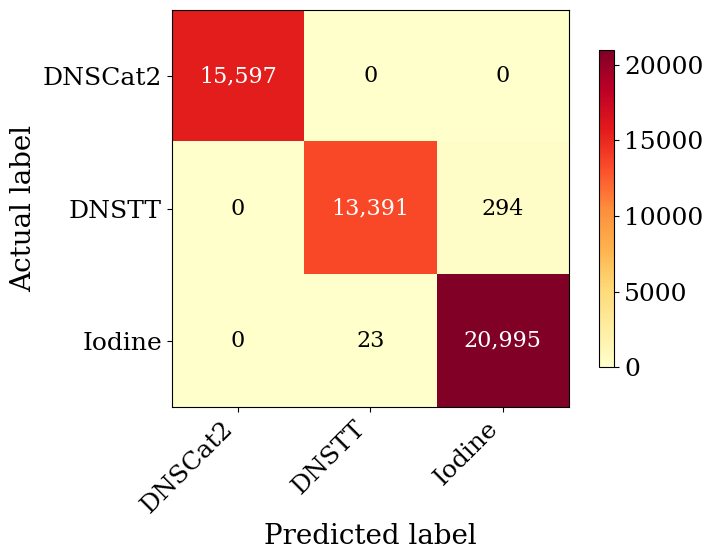


Saved: cascade_confusion_matrix.pdf


In [36]:
# =====================================================================
# 35. END-TO-END CASCADE EVALUATION
# =====================================================================
#
# Stage 1 classifies every test flow as Benign or Malicious.
# Only flows flagged as Malicious proceed to Stage 2.
# Flows classified as Benign are NEVER sent to Stage 2.
#
# Stage 2 attributes each flagged flow to DNSCat2, DNSTT, or Iodine.
#
# The confusion matrix is 3-class (DNSCat2, DNSTT, Iodine),
# evaluated over truly malicious flows that Stage 1 forwarded.
# Malicious flows missed by Stage 1 are reported separately.
# =====================================================================

# ---- Reconstruct the same test split with tool labels attached ----

stage1_full = data[FEATURE_COLUMNS + ["Class", "Label"]].copy()

stage1_full["Target"] = (
    stage1_full["Class"].str.lower().map({"benign": 0, "malicious": 1})
)

stage1_full = stage1_full.dropna(subset=["Target"]).reset_index(drop=True)
stage1_full["Target"] = stage1_full["Target"].astype(int)

(
    casc_X_train, casc_X_val, casc_X_test,
    casc_y_train, casc_y_val, casc_y_test
) = create_three_way_split(
    stage1_full[FEATURE_COLUMNS + ["Label"]],
    stage1_full["Target"],
    random_state=RANDOM_STATE
)

# Ground-truth tool label for every test flow
casc_tool_truth = casc_X_test["Label"].to_numpy()
casc_features_test = casc_X_test[FEATURE_COLUMNS]

total_test_flows = len(casc_features_test)
actually_malicious = (casc_y_test.to_numpy() == 1)
actually_benign = ~actually_malicious
n_truly_malicious = int(actually_malicious.sum())
n_truly_benign = int(actually_benign.sum())

print("=" * 70)
print("END-TO-END CASCADE EVALUATION")
print("=" * 70)
print(f"\nTotal test flows : {total_test_flows}")
print(f"Truly Benign     : {n_truly_benign}")
print(f"Truly Malicious  : {n_truly_malicious}")

# ---- STAGE 1: Classify every test flow as Benign (0) or Malicious (1) ----

stage1_preds = stage1_best_model.predict(casc_features_test)

predicted_benign_mask = (stage1_preds == 0)
predicted_malicious_mask = (stage1_preds == 1)

n_predicted_benign = int(predicted_benign_mask.sum())
n_predicted_malicious = int(predicted_malicious_mask.sum())

print(f"\n--- Stage 1 ---")
print(f"Predicted Benign   (NOT sent to Stage 2): {n_predicted_benign}")
print(f"Predicted Malicious (sent to Stage 2)   : {n_predicted_malicious}")

# ---- Error accounting at Stage 1 ----

missed_by_stage1 = int((predicted_benign_mask & actually_malicious).sum())
benign_falsely_flagged = int((predicted_malicious_mask & actually_benign).sum())

print(f"\nMalicious flows missed by Stage 1 (FN)       : {missed_by_stage1}")
print(f"Benign flows falsely sent to Stage 2 (FP)    : {benign_falsely_flagged}")
print(f"Malicious flows correctly forwarded to Stage 2: "
      f"{n_predicted_malicious - benign_falsely_flagged}")

# ---- STAGE 2: Classify ONLY flows flagged as Malicious by Stage 1 ----

tool_index_to_name = {0: "DNSCat2", 1: "DNSTT", 2: "Iodine"}

# Default: every flow is labeled Benign by Stage 1
final_predictions = np.full(total_test_flows, "Benign", dtype=object)

if n_predicted_malicious > 0:
    flagged_features = casc_features_test.loc[predicted_malicious_mask]

    stage2_preds_idx = stage2_best_model.predict(flagged_features)
    stage2_preds_names = np.array([
        tool_index_to_name[i] for i in stage2_preds_idx
    ])

    # Overwrite ONLY the flagged flows with Stage 2 predictions
    final_predictions[predicted_malicious_mask] = stage2_preds_names

    print(f"\n--- Stage 2 (applied to {n_predicted_malicious} flagged flows) ---")
    for tool_name in ["DNSCat2", "DNSTT", "Iodine"]:
        count = int((stage2_preds_names == tool_name).sum())
        print(f"  Attributed to {tool_name:8s}: {count}")
else:
    print("\nNo flows flagged as malicious — Stage 2 was not invoked.")

# ---- Verify: benign-predicted flows never touched Stage 2 ----

assert all(final_predictions[predicted_benign_mask] == "Benign"), \
    "ERROR: Some benign-predicted flows were sent to Stage 2!"

print(f"\nVerification: all {n_predicted_benign} benign-predicted flows "
      f"retained their Benign label. Stage 2 was never applied to them.")

# ---- 3-class confusion matrix over truly malicious flows forwarded ----
#
# Scope: only flows that are (a) truly malicious AND (b) Stage 1
# correctly flagged as malicious.  Missed flows are reported above;
# the CM below shows Stage 2 attribution quality on what it received.

forwarded_malicious_mask = (predicted_malicious_mask & actually_malicious)
n_forwarded_malicious = int(forwarded_malicious_mask.sum())

forwarded_truth = casc_tool_truth[forwarded_malicious_mask]
forwarded_preds = final_predictions[forwarded_malicious_mask]

tool_classes = ["DNSCat2", "DNSTT", "Iodine"]

cascade_cm = confusion_matrix(
    forwarded_truth,
    forwarded_preds,
    labels=tool_classes
)

cascade_cm_df = pd.DataFrame(
    cascade_cm,
    index=[f"True {c}" for c in tool_classes],
    columns=[f"Pred {c}" for c in tool_classes]
)

print(f"\n--- 3-Class End-to-End Confusion Matrix ---")
print(f"(over {n_forwarded_malicious} truly malicious flows forwarded "
      f"by Stage 1)\n")
display(cascade_cm_df)

# ---- Per-class metrics ----

cascade_report = classification_report(
    forwarded_truth,
    forwarded_preds,
    labels=tool_classes,
    target_names=tool_classes,
    digits=4,
    zero_division=0
)

print(f"\n--- Per-Class Metrics ---\n")
print(cascade_report)

# ---- Summary metrics ----

cascade_attribution_accuracy = accuracy_score(forwarded_truth, forwarded_preds)
cascade_macro_f1 = f1_score(
    forwarded_truth, forwarded_preds,
    labels=tool_classes, average="macro", zero_division=0
)

# Also count missed malicious flows as attribution errors
all_malicious_truth = casc_tool_truth[actually_malicious]
all_malicious_preds = final_predictions[actually_malicious]
cascade_accuracy_incl_missed = (
    (all_malicious_preds == all_malicious_truth).mean()
)

stage2_isolated_acc = accuracy_score(
    y2_test, stage2_best_model.predict(X2_test)
)

print(f"--- Summary ---")
print(f"Cascade attribution accuracy (forwarded malicious): "
      f"{cascade_attribution_accuracy:.6f}  "
      f"({cascade_attribution_accuracy*100:.4f}%)")
print(f"Cascade attribution accuracy (all malicious, "
      f"missed = error)    : "
      f"{cascade_accuracy_incl_missed:.6f}  "
      f"({cascade_accuracy_incl_missed*100:.4f}%)")
print(f"Cascade macro F1 (forwarded malicious)             : "
      f"{cascade_macro_f1:.6f}  ({cascade_macro_f1*100:.4f}%)")
print(f"Stage 2 isolated accuracy (reference)              : "
      f"{stage2_isolated_acc:.6f}  ({stage2_isolated_acc*100:.4f}%)")

# ---- Save CSV summaries ----

cascade_summary = pd.DataFrame([{
    "TotalTestFlows": total_test_flows,
    "TrulyBenign": n_truly_benign,
    "TrulyMalicious": n_truly_malicious,
    "Stage1_PredictedBenign": n_predicted_benign,
    "Stage1_PredictedMalicious_SentToStage2": n_predicted_malicious,
    "Stage1_MaliciousMissed_FN": missed_by_stage1,
    "Stage1_BenignFlagged_FP": benign_falsely_flagged,
    "MaliciousForwardedToStage2": n_forwarded_malicious,
    "CascadeAttributionAcc_forwarded": round(
        cascade_attribution_accuracy, 6
    ),
    "CascadeAttributionAcc_allMalicious": round(
        cascade_accuracy_incl_missed, 6
    ),
    "CascadeMacroF1_forwarded": round(cascade_macro_f1, 6),
    "Stage2_IsolatedAccuracy_ref": round(stage2_isolated_acc, 6),
}])

cascade_summary.to_csv(
    OUTPUT_DIR / "cascade_evaluation.csv",
    index=False
)

cascade_cm_df.to_csv(
    OUTPUT_DIR / "cascade_confusion_matrix.csv"
)

print(f"\nSaved: cascade_evaluation.csv")
print(f"Saved: cascade_confusion_matrix.csv")

display(cascade_summary)

# ---- Plot 3-class confusion matrix ----

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(cascade_cm, cmap="YlOrRd")

ax.set_xticks(range(len(tool_classes)))
ax.set_yticks(range(len(tool_classes)))
ax.set_xticklabels(tool_classes, rotation=45, ha="right")
ax.set_yticklabels(tool_classes)
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")

for i in range(len(tool_classes)):
    for j in range(len(tool_classes)):
        value = cascade_cm[i, j]
        color = "white" if value > cascade_cm.max() / 2 else "black"
        ax.text(j, i, f"{value:,}", ha="center", va="center",
                color=color, fontsize=16)

fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "cascade_confusion_matrix.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("\nSaved: cascade_confusion_matrix.pdf")


In [37]:
# =====================================================================
# 36. HYPERPARAMETER EXPORT FOR THE REPRODUCIBILITY TABLE
# =====================================================================

import sklearn

hyperparameter_rows = []

for model_name, model_template in MODELS.items():

    classifier = model_template.named_steps["classifier"]

    hyperparameter_rows.append({
        "Model": model_name,
        "Class": type(classifier).__name__,
        "Parameters": str(classifier.get_params()),
    })

hyperparameters_df = pd.DataFrame(hyperparameter_rows)

hyperparameters_df["sklearn_version"] = sklearn.__version__
hyperparameters_df["numpy_version"] = np.__version__
hyperparameters_df["pandas_version"] = pd.__version__

hyperparameters_df.to_csv(
    OUTPUT_DIR / "model_hyperparameters.csv",
    index=False
)

print("\nHyperparameters exported for the reproducibility table.")
display(hyperparameters_df)


Hyperparameters exported for the reproducibility table.


,Model,Class,Parameters,sklearn_version,numpy_version,pandas_version
0,Logistic Regression,LogisticRegression,"{'C': 1.0, 'class_weight': 'balanced', 'dual':...",1.6.1,2.0.2,2.2.2
1,Decision Tree,DecisionTreeClassifier,"{'ccp_alpha': 0.0, 'class_weight': 'balanced',...",1.6.1,2.0.2,2.2.2
2,Random Forest,RandomForestClassifier,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w...",1.6.1,2.0.2,2.2.2
3,SVM,LinearSVC,"{'C': 1.0, 'class_weight': 'balanced', 'dual':...",1.6.1,2.0.2,2.2.2


In [38]:
# =====================================================================
# 37. CREATE ZIP FILES
# =====================================================================

kde_zip_path = shutil.make_archive(
    base_name=str(
        BASE_DIR /
        "kde_plots_600dpi"
    ),
    format="zip",
    root_dir=str(KDE_DIR)
)


complete_output_zip_path = (
    shutil.make_archive(
        base_name=str(
            BASE_DIR /
            "two_stage_classification_output"
        ),
        format="zip",
        root_dir=str(OUTPUT_DIR)
    )
)


print("\nKDE ZIP file:")
print(kde_zip_path)


print("\nComplete output ZIP file:")
print(complete_output_zip_path)


KDE ZIP file:
/content/drive/MyDrive/Objective2/kde_plots_600dpi.zip

Complete output ZIP file:
/content/drive/MyDrive/Objective2/two_stage_classification_output.zip


In [39]:
# =====================================================================
# 38. FINAL SUMMARY
# =====================================================================

print("\n" + "=" * 72)
print("PIPELINE COMPLETED")
print("=" * 72)


print("\nInput folder:")
print(BASE_DIR)


print("\nOutput folder:")
print(OUTPUT_DIR)


print("\nKDE PDF folder:")
print(KDE_DIR)


print("\nNumber of KDE PDFs:")
print(
    len(
        list(
            KDE_DIR.glob("*.pdf")
        )
    )
)


print("\nStage-1 results:")
print(STAGE1_DIR)


print("\nStage-2 results:")
print(STAGE2_DIR)


print("\nCleaned datasets:")
print(CLEANED_DATA_DIR)


print("\nSaved models:")
print(MODEL_DIR)


print("\nStage-1 best model:")
print(stage1_best_model_name)


print("\nStage-2 best model:")
print(stage2_best_model_name)


print("\nCross-validation results:")
print(OUTPUT_DIR / "cross_validation_results.csv")


print("\nStage-1 ResponseTime ablation:")
print(STAGE1_DIR / "stage1_responsetime_ablation.csv")


print("\nCascade evaluation:")
print(OUTPUT_DIR / "cascade_evaluation.csv")


print("\nModel hyperparameters:")
print(OUTPUT_DIR / "model_hyperparameters.csv")


print("\nKDE plots ZIP:")
print(kde_zip_path)


print("\nComplete results ZIP:")
print(complete_output_zip_path)


PIPELINE COMPLETED

Input folder:
/content/drive/MyDrive/Objective2

Output folder:
/content/drive/MyDrive/Objective2/output_cascading

KDE PDF folder:
/content/drive/MyDrive/Objective2/output_cascading/caskde_plots

Number of KDE PDFs:
29

Stage-1 results:
/content/drive/MyDrive/Objective2/output_cascading/casstage1_results

Stage-2 results:
/content/drive/MyDrive/Objective2/output_cascading/casstage2_results

Cleaned datasets:
/content/drive/MyDrive/Objective2/output_cascading/cascleaned_data

Saved models:
/content/drive/MyDrive/Objective2/output_cascading/cassaved_models

Stage-1 best model:
Random Forest

Stage-2 best model:
Random Forest

Cross-validation results:
/content/drive/MyDrive/Objective2/output_cascading/cross_validation_results.csv

Stage-1 ResponseTime ablation:
/content/drive/MyDrive/Objective2/output_cascading/casstage1_results/stage1_responsetime_ablation.csv

Cascade evaluation:
/content/drive/MyDrive/Objective2/output_cascading/cascade_evaluation.csv

Model hype